# Práctica 4 - Anatomía de un dataset de Machine Learning
**Sesión 4 - El dataset**

## Objetivos
Analizar un dataset desde el punto de vista de Machine Learning: muestras, variables, identificadores, características, target, \(X\), \(y\), tipos conceptuales, valores ausentes y distribuciones.

> El objetivo principal no es escribir mucho código, sino **interpretar correctamente los datos**.

## Contexto
Una plataforma de comercio electrónico dispone de información histórica sobre sus clientes. Trabajaremos con `clientes_ecommerce.csv`.

| Variable | Descripción |
|---|---|
| `cliente_id` | Identificador único |
| `edad` | Edad |
| `antiguedad_meses` | Meses desde el registro |
| `ingresos_anuales` | Ingresos anuales estimados |
| `gasto_mensual` | Gasto medio mensual |
| `num_compras` | Compras del último año |
| `devoluciones` | Devoluciones del último año |
| `dispositivo` | Dispositivo principal |
| `zona` | Zona de residencia |
| `nivel_fidelidad` | Bronce, Plata, Oro o Platino |
| `satisfaccion` | Valoración de 1 a 5 |
| `compra_proximo_mes` | Compra el mes siguiente: Sí/No |

Completa las celdas `# TODO` y responde en Markdown.

## Preparación

In [ ]:
# TODO: importa NumPy, pandas y matplotlib.pyplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en df
df = pd.read_csv('clientes_ecommerce.csv')

## Parte 1 - Comprender el dataset
### Ejercicio 1 - Primera inspección
Muestra las primeras 10 filas.

In [ ]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


### Respuesta
1. ¿Qué representa una fila?
2. ¿Qué representa una columna?
3. ¿Cuál es la unidad de observación?
4. ¿Todas las columnas son características? Justifica.

**Respuesta:**
1. Un cliente de la tienda online.
2. Un dato del cliente (edad, gasto, zona...).
3. El cliente.
4. No. `cliente_id` solo identifica al cliente y `compra_proximo_mes` es lo que queremos predecir (el target).

### Ejercicio 2 - Dimensiones
Obtén `df.shape`.

In [ ]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

### Respuesta
- Número de muestras: 400
- Número de columnas: 12
- ¿Tenemos el mismo número de características? ¿Por qué?
  - No, son 10. Hay que quitar `cliente_id` y el target.

## Parte 2 - Clasificación de variables
### Ejercicio 3 - Tipos almacenados

In [ ]:
# TODO: consulta df.dtypes
df.dtypes

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object

### Ficha de variables
Clasifica cada variable como: **Identificador, Numérica discreta, Numérica continua, Categórica nominal, Categórica ordinal o Target**.

| Variable | dtype | Tipo conceptual | ¿Feature candidata? |
|---|---|---|---|
| cliente_id | int64 | Identificador | No |
| edad | int64 | Numérica discreta | Sí |
| antiguedad_meses | float64 | Numérica discreta | Sí |
| ingresos_anuales | float64 | Numérica continua | Sí |
| gasto_mensual | float64 | Numérica continua | Sí |
| num_compras | int64 | Numérica discreta | Sí |
| devoluciones | int64 | Numérica discreta | Sí |
| dispositivo | str | Categórica nominal | Sí |
| zona | str | Categórica nominal | Sí |
| nivel_fidelidad | str | Categórica ordinal | Sí |
| satisfaccion | int64 | Categórica ordinal | Sí |
| compra_proximo_mes | str | Target | No |

No clasifiques únicamente por `dtype`.

`antiguedad_meses` sale como float solo porque tiene huecos (NaN), pero son meses enteros.

### Ejercicio 4 - `cliente_id`
Muestra sus primeros 10 valores.

In [ ]:
# TODO: analiza cliente_id
print(df['cliente_id'].head(10).tolist())
print("dtype:", df['cliente_id'].dtype)
print("Valores distintos:", df['cliente_id'].nunique(), "de", len(df))

[20001, 20002, 20003, 20004, 20005, 20006, 20007, 20008, 20009, 20010]
dtype: int64
Valores distintos: 400 de 400


### Respuesta
1. ¿Qué dtype tiene?
2. ¿Es por ello cuantitativa?
3. ¿Tiene sentido calcular su media?
4. ¿La incluirías inicialmente en \(X\)?
5. Justifica.

**Respuesta:**
1. int64.
2. No, que sean números no la hace cuantitativa.
3. No, la media de un id no significa nada.
4. No.
5. Cada cliente tiene uno distinto (400 de 400), así que no dice nada sobre si va a comprar. Solo sirve para saber quién es quién.

### Ejercicio 5 - `satisfaccion`
Muestra la frecuencia de sus valores ordenados.

In [ ]:
# TODO: value_counts() + sort_index()
df['satisfaccion'].value_counts().sort_index()

satisfaccion
1     33
2     58
3    123
4    116
5     70
Name: count, dtype: int64

Sabemos que 1 = Muy insatisfecho, 2 = Insatisfecho, 3 = Neutral, 4 = Satisfecho y 5 = Muy satisfecho.

### Respuesta
1. ¿Cómo la almacena pandas?
2. ¿Es simplemente numérica?
3. ¿Existe un orden?
4. ¿Nominal u ordinal?
5. Explica `dtype` frente a significado conceptual.

**Respuesta:**
1. Como int64.
2. No.
3. Sí, va de 1 (muy insatisfecho) a 5 (muy satisfecho).
4. Ordinal.
5. El dtype es solo cómo guarda pandas el dato. Aquí los números son etiquetas con orden, no cantidades: un 4 no es "el doble de satisfecho" que un 2.

## Parte 3 - Calidad de los datos
### Ejercicio 6 - Información estructural

In [ ]:
# TODO: utiliza df.info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Respuesta
1. ¿Cuántas muestras hay?
2. ¿Qué tipos técnicos aparecen?
3. ¿Todas las columnas tienen los mismos valores no nulos?
4. ¿Qué columnas contienen ausentes?
5. ¿Cuántos faltan?

**Respuesta:**
1. 400.
2. int64, float64 y str.
3. No.
4. `antiguedad_meses`, `ingresos_anuales` y `gasto_mensual`.
5. 5, 4 y 3 respectivamente (12 en total).

### Ejercicio 7 - Valores ausentes
Calcula cantidad y porcentaje por columna.

In [ ]:
# TODO: valores ausentes por columna
ausentes = df.isna().sum()
print(ausentes)

# TODO: porcentaje de ausentes por columna
print((ausentes / len(df) * 100).round(2))

cliente_id            0
edad                  0
antiguedad_meses      5
ingresos_anuales      4
gasto_mensual         3
num_compras           0
devoluciones          0
dispositivo           0
zona                  0
nivel_fidelidad       0
satisfaccion          0
compra_proximo_mes    0
dtype: int64
cliente_id            0.00
edad                  0.00
antiguedad_meses      1.25
ingresos_anuales      1.00
gasto_mensual         0.75
num_compras           0.00
devoluciones          0.00
dispositivo           0.00
zona                  0.00
nivel_fidelidad       0.00
satisfaccion          0.00
compra_proximo_mes    0.00
dtype: float64


### Reflexión
¿Es lo mismo que falten 5 valores entre 50 muestras que entre 100.000? ¿Por qué son útiles los porcentajes?

No. 5 de 50 es un 10 %, que es bastante; 5 de 100.000 no es casi nada. Con el porcentaje se ve lo grave que es sin importar el tamaño del dataset. Aquí lo máximo es un 1.25 % (`antiguedad_meses`).

## Parte 4 - Construcción de X e y
Queremos predecir: **¿realizará el cliente una compra el próximo mes?**

### Ejercicio 8 - Variable objetivo

In [ ]:
# TODO: crea y
y = df['compra_proximo_mes']

# TODO: muestra y.head() y y.shape
print(y.head())
print(y.shape)

0    No
1    No
2    Sí
3    Sí
4    No
Name: compra_proximo_mes, dtype: str
(400,)


### Respuesta
1. ¿Qué representa cada elemento de \(y\)?
2. ¿Cuántos contiene?
3. ¿Por qué el target no debe incluirse también en \(X\)?

**Respuesta:**
1. Si ese cliente compró o no el mes siguiente (`Sí`/`No`).
2. 400.
3. Porque sería darle la respuesta al modelo. Aprendería a copiarla y luego con clientes nuevos no serviría para nada.

### Ejercicio 9 - Construir \(X\)
Usa: `edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad`, `satisfaccion`.

No incluyas `cliente_id` ni `compra_proximo_mes`.

In [ ]:
# TODO: crea X
X = df[['edad', 'antiguedad_meses', 'ingresos_anuales', 'gasto_mensual',
        'num_compras', 'devoluciones', 'dispositivo', 'zona',
        'nivel_fidelidad', 'satisfaccion']]

# TODO: muestra X.head() y X.shape
display(X.head())
print(X.shape)

,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion
0,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5
1,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2
2,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5
3,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4
4,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4


(400, 10)


### Ejercicio 10 - Dimensiones
Completa y explica:

- \(n =\) 400 (clientes)
- \(p =\) 10 (características)
- \(X.shape =\) (400, 10)
- \(y.shape =\) (400,)

`y` es una sola columna, por eso solo tiene una dimensión. Las dos tienen 400 filas porque cada fila es el mismo cliente.

## Parte 5 - ¿Está etiquetado?
### Ejercicio 11
1. ¿Tenemos \(X\)?
2. ¿Tenemos \(y\)?
3. ¿Está etiquetado?
4. ¿Puede usarse para aprendizaje supervisado?
5. ¿Qué tipo de problema es predecir `compra_proximo_mes`?
6. ¿Binario o multiclase?
7. ¿Cuáles son las clases?

**Respuesta:**
1. Sí.
2. Sí, `compra_proximo_mes`.
3. Sí, cada cliente tiene su respuesta.
4. Sí.
5. Clasificación.
6. Binaria.
7. `Sí` y `No`.

## Parte 6 - Distribuciones
### Ejercicio 12 - Variables categóricas
Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes` con frecuencias absolutas y relativas.

In [ ]:
# TODO: value_counts() y value_counts(normalize=True) para las cuatro variables
for col in ['dispositivo', 'zona', 'nivel_fidelidad', 'compra_proximo_mes']:
    print(df[col].value_counts())
    print((df[col].value_counts(normalize=True) * 100).round(2))
    print()

dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        60.50
Ordenador    33.25
Tablet        6.25
Name: proportion, dtype: float64

zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
zona
Este      22.25
Sur       20.00
Norte     19.75
Oeste     19.00
Centro    19.00
Name: proportion, dtype: float64

nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
nivel_fidelidad
Bronce     40.50
Plata      26.25
Oro        20.75
Platino    12.50
Name: proportion, dtype: float64

compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64
compra_proximo_mes
No    61.5
Sí    38.5
Name: proportion, dtype: float64



### Tabla resumen
| Variable | Categoría más frecuente | Frecuencia | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60.50 % |
| zona | Este | 89 | 22.25 % |
| nivel_fidelidad | Bronce | 162 | 40.50 % |
| compra_proximo_mes | No | 246 | 61.50 % |

### Ejercicio 13 - Visualización del target
Crea un gráfico de barras con título y etiquetas.

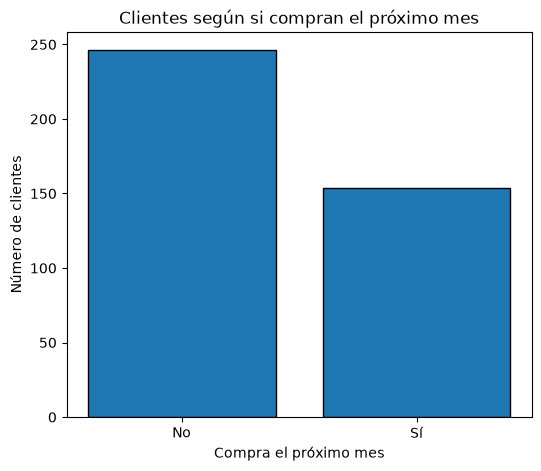

In [ ]:
# TODO: gráfico de barras
conteo_compra = df['compra_proximo_mes'].value_counts()

plt.figure(figsize=(6, 5))
plt.bar(conteo_compra.index, conteo_compra.values, edgecolor='black')
plt.title('Clientes según si compran el próximo mes')
plt.xlabel('Compra el próximo mes')
plt.ylabel('Número de clientes')
plt.show()

### Interpretación
¿Las clases aparecen aproximadamente con la misma frecuencia? Justifica con datos.

No. Hay 246 clientes que no compran (61.5 %) y 154 que sí (38.5 %). No es un desequilibrio enorme, pero hay bastantes más `No`.

## Parte 7 - Variables numéricas
### Ejercicio 14 - Estadística descriptiva
Analiza `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras` y `devoluciones`.

In [ ]:
# TODO: describe() solo sobre las columnas indicadas
df[['edad', 'ingresos_anuales', 'gasto_mensual', 'num_compras', 'devoluciones']].describe().round(2)

,edad,ingresos_anuales,gasto_mensual,num_compras,devoluciones
count,400.00,396.00,397.00,400.00,400.00
mean,46.40,36440.92,69.09,8.22,1.23
std,18.01,14325.23,39.02,2.78,1.14
min,18.00,9000.00,5.77,2.00,0.00
25%,33.00,26034.09,39.72,6.00,0.00
50%,45.00,36817.27,61.17,8.00,1.00
75%,59.00,45969.03,90.15,10.00,2.00
max,195.00,82925.37,260.00,17.00,5.00


### Interpretación
Escribe una conclusión breve para cada variable:
- **edad:** media de 46 años y mediana de 45, pero el máximo es 195, que es imposible.
- **ingresos_anuales:** unos 36.400 € de media, de 9.000 a casi 83.000 €. Faltan 4 valores.
- **gasto_mensual:** 69 € de media y 61 € de mediana; hay clientes que gastan mucho (hasta 260 €) y suben la media.
- **num_compras:** unas 8 compras al año, entre 2 y 17.
- **devoluciones:** poco más de 1 de media; la mitad devuelve 1 o menos.

### Ejercicio 15 - Detectar algo sospechoso
1. ¿Hay algún valor poco razonable?
2. ¿En qué variable?
3. ¿Por qué es sospechoso?
4. ¿Lo eliminarías inmediatamente?
5. ¿Qué comprobarías antes?

**Respuesta:**
1. Sí.
2. En `edad`.
3. Hay un cliente con 195 años, nadie vive tanto.
4. No.
5. Miraría el registro original por si es una errata (19, 95...). Si no se puede saber, lo trataría como valor ausente.

## Parte 8 - Distribuciones numéricas
### Ejercicio 16
Crea histogramas independientes de `edad`, `ingresos_anuales`, `gasto_mensual` y `num_compras`.

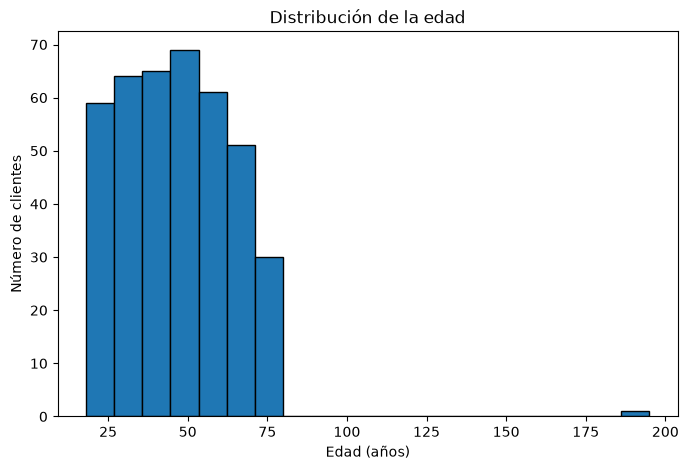

In [ ]:
# TODO: histograma de edad
plt.figure(figsize=(8, 5))
plt.hist(df['edad'].dropna(), bins=20, edgecolor='black')
plt.title('Distribución de la edad')
plt.xlabel('Edad (años)')
plt.ylabel('Número de clientes')
plt.show()

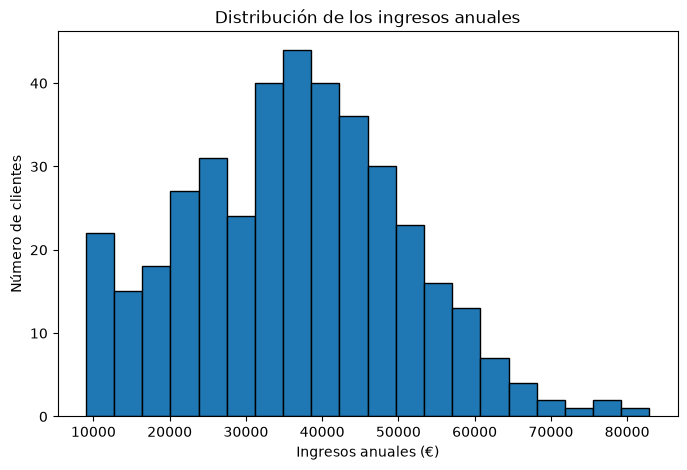

In [ ]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(8, 5))
plt.hist(df['ingresos_anuales'].dropna(), bins=20, edgecolor='black')
plt.title('Distribución de los ingresos anuales')
plt.xlabel('Ingresos anuales (€)')
plt.ylabel('Número de clientes')
plt.show()

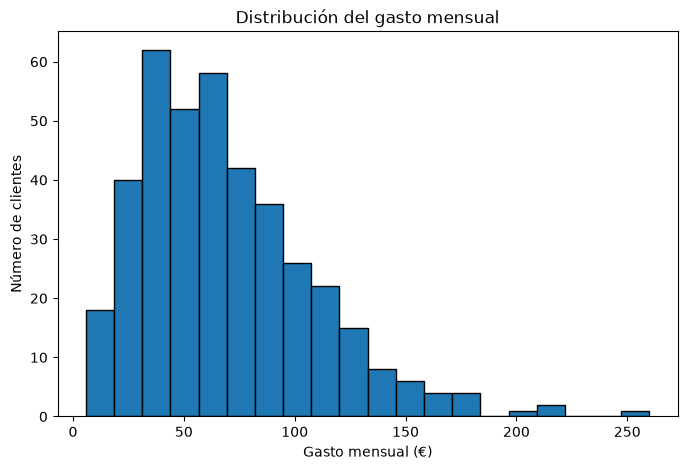

In [ ]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(8, 5))
plt.hist(df['gasto_mensual'].dropna(), bins=20, edgecolor='black')
plt.title('Distribución del gasto mensual')
plt.xlabel('Gasto mensual (€)')
plt.ylabel('Número de clientes')
plt.show()

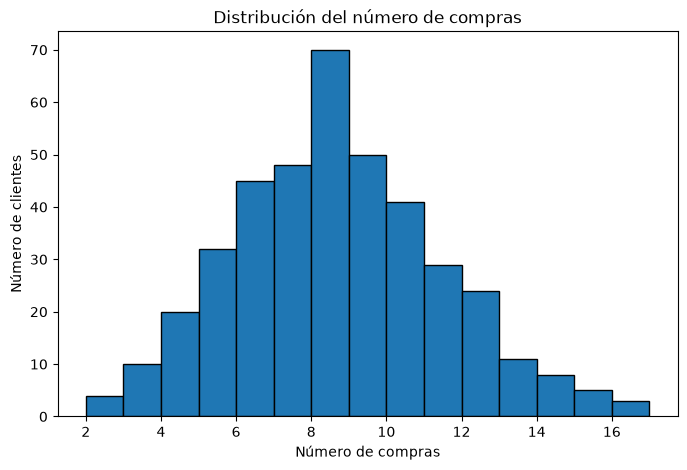

In [ ]:
# TODO: histograma de num_compras
plt.figure(figsize=(8, 5))
plt.hist(df['num_compras'].dropna(), bins=15, edgecolor='black')
plt.title('Distribución del número de compras')
plt.xlabel('Número de compras')
plt.ylabel('Número de clientes')
plt.show()

### Observaciones
- **edad:** casi todos están entre 18 y 75 años bastante repartidos, pero el 195 estira el eje y se queda solo a la derecha.
- **ingresos_anuales:** la mayoría está entre 20.000 y 50.000 €. Hay un pico raro en 9.000 € (16 clientes justo con ese valor).
- **gasto_mensual:** se concentra entre 20 y 100 € y tiene cola a la derecha, unos pocos gastan más de 165 €.
- **num_compras:** forma de campana, la mayoría entre 6 y 10 compras.

### Ejercicio 17 - Problema A
> ¿Realizará el cliente una compra el próximo mes?

Completa y justifica:
- Target: `compra_proximo_mes`.
- ¿Existe \(y\)?: Sí, la columna ya está en el dataset.
- Supervisado / no supervisado: supervisado, porque tenemos la respuesta de cada cliente.
- Clasificación / regresión / clustering: clasificación, el target es una categoría.
- Binaria / multiclase: binaria, solo `Sí` o `No`.

### Ejercicio 18 - Problema B
Supón una columna `gasto_proximo_mes` con cantidades monetarias.

> ¿Cuánto gastará el cliente el próximo mes?

1. ¿Cuál sería \(y\)?
2. ¿Qué tipo de variable?
3. ¿Supervisado?
4. ¿Clasificación o regresión?
5. ¿Por qué?

**Respuesta:**
1. `gasto_proximo_mes`.
2. Numérica continua (euros).
3. Sí.
4. Regresión.
5. Porque queremos predecir una cantidad de dinero, no una categoría.

### Ejercicio 19 - Problema C
> Descubrir grupos de clientes similares sin grupos definidos previamente.

1. ¿Existe etiqueta de grupo?
2. ¿Necesitamos \(y\)?
3. ¿Supervisado o no supervisado?
4. ¿Qué técnica usaríamos?
5. ¿Qué variables podrían describir los grupos?

**Respuesta:**
1. No.
2. No.
3. No supervisado.
4. Clustering (por ejemplo K-means).
5. `gasto_mensual`, `num_compras`, `ingresos_anuales`, `antiguedad_meses`, `devoluciones` o `nivel_fidelidad`.

## Parte 10 - Razonamiento
### Ejercicio 20 - ¿Una columna puede cambiar de papel?
¿Por qué una misma variable puede actuar como característica en un problema y como objetivo en otro?

**Respuesta:** Porque el papel lo decide la pregunta, no la columna. En el problema A el gasto es una característica más, y en el B el gasto del mes siguiente es justo lo que queremos predecir.

### Ejercicio 21 - ¿Qué está mal aquí?
Un compañero hace:

```python
X = df.drop(columns=["compra_proximo_mes"])
y = df["compra_proximo_mes"]
```

y afirma que todas las columnas de `X` ya son características adecuadas.

¿Estás de acuerdo? Identifica al menos dos cuestiones que revisarías.

**Respuesta:** No.
1. `cliente_id` se queda en `X` y es solo un identificador.
2. Hay valores ausentes y una edad de 195 que hay que tratar antes.
3. `dispositivo`, `zona` y `nivel_fidelidad` son texto y hay que pasarlas a números.

## Parte 11 - Ficha técnica
### Ejercicio 22

```text
FICHA DEL DATASET
=================
Nombre: Clientes e-commerce
Número de muestras: 400
Número de columnas: 12
Unidad de observación: cliente
Identificador: cliente_id
Target: compra_proximo_mes
Tipo de target: categórica binaria (Sí/No)
Número de features candidatas: 10
Features numéricas: edad, antiguedad_meses, ingresos_anuales, gasto_mensual, num_compras, devoluciones
Features categóricas nominales: dispositivo, zona
Features ordinales: nivel_fidelidad, satisfaccion
Datos etiquetados: Sí
Valores ausentes: 12 (antiguedad_meses 5, ingresos_anuales 4, gasto_mensual 3)
Problema principal: predecir si el cliente comprará el próximo mes
Tipo de aprendizaje: supervisado
Tipo de tarea: clasificación binaria
```

## Parte 12 - Conclusiones
### Ejercicio 23
Escribe entre **10 y 15 líneas** incluyendo: muestra, dimensiones, columnas vs. features, identificador, tipos de variables, target, \(X\), \(y\), etiquetado, ausentes, distribuciones, posible problema de calidad y tipo de problema de ML.

### Conclusiones
El dataset tiene 400 clientes y 12 columnas.
Cada fila es un cliente.
De las 12 columnas solo 10 son características: `cliente_id` es un identificador y `compra_proximo_mes` el target.
Hay variables numéricas (edad, ingresos, gasto...), nominales (dispositivo, zona) y ordinales (nivel de fidelidad, satisfacción).
`satisfaccion` es número pero en realidad es una escala con orden.
`X` tiene forma (400, 10) e `y` (400,).
Los datos están etiquetados, así que se puede hacer aprendizaje supervisado.
Hay 12 valores ausentes repartidos entre antigüedad, ingresos y gasto.
La mayoría usa el móvil y el nivel más común es Bronce.
El 61.5 % no compra el mes siguiente, las clases no están equilibradas.
El gasto mensual tiene cola a la derecha.
Hay una edad de 195 años que parece un error y 16 clientes con ingresos de 9.000 justos.
Es un problema de clasificación binaria.

# Ampliación opcional - El reto del analista
Mediante pandas, responde e interpreta:

1. ¿Qué nivel de fidelidad presenta mayor gasto mensual medio?
2. ¿El gasto histórico medio difiere entre quienes compran el mes siguiente y quienes no?
3. ¿Qué dispositivo tiene mayor número medio de compras?
4. ¿Cuál es la satisfacción media por nivel de fidelidad?
5. ¿Qué porcentaje de clientes de cada nivel compra el mes siguiente?

> Una asociación no demuestra causalidad.

In [ ]:
# TODO: ampliación opcional
# 1. Gasto mensual medio por nivel de fidelidad
print(df.groupby('nivel_fidelidad')['gasto_mensual'].mean().round(2).sort_values(ascending=False))
print()

# 2. Gasto medio según compra_proximo_mes
print(df.groupby('compra_proximo_mes')['gasto_mensual'].mean().round(2))
print()

# 3. Compras medias por dispositivo
print(df.groupby('dispositivo')['num_compras'].mean().round(2))
print()

# 4. Satisfacción media por nivel de fidelidad
print(df.groupby('nivel_fidelidad')['satisfaccion'].mean().round(2))
print()

# 5. Porcentaje de clientes de cada nivel que compran el mes siguiente
print((pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'], normalize='index') * 100).round(2))

nivel_fidelidad
Oro        70.93
Platino    69.70
Plata      68.69
Bronce     68.20
Name: gasto_mensual, dtype: float64

compra_proximo_mes
No    64.59
Sí    76.34
Name: gasto_mensual, dtype: float64

dispositivo
Móvil        8.21
Ordenador    8.24
Tablet       8.24
Name: num_compras, dtype: float64

nivel_fidelidad
Bronce     3.31
Oro        3.37
Plata      3.37
Platino    3.24
Name: satisfaccion, dtype: float64

compra_proximo_mes     No     Sí
nivel_fidelidad                 
Bronce              69.14  30.86
Oro                 62.65  37.35
Plata               60.00  40.00
Platino             38.00  62.00


### Respuesta
1. Oro, con unos 71 €, aunque todos los niveles están entre 68 y 71 €.
2. Sí, los que compran gastaban de media unos 76 € y los que no unos 65 €.
3. Prácticamente igual en los tres, unas 8.2 compras.
4. Todos rondan el 3.3, no cambia casi nada.
5. Bronce 31 %, Plata 40 %, Oro 37 % y Platino 62 %. Los Platino compran mucho más, pero eso no quiere decir que el nivel sea la causa.

# Antes de entregar
- Completa todos los `TODO`.
- Responde las preguntas en Markdown.
- Añade títulos y etiquetas a los gráficos.
- Ejecuta el notebook completo desde el principio y comprueba que no hay errores.
- Justifica tus decisiones.

**Nombre recomendado:** `Practica_04_Apellido_Nombre.ipynb`